C:\Users\a2189\AppData\Local\Temp\ipykernel_33020\994008811.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='Group', y='Concentration', data=df,


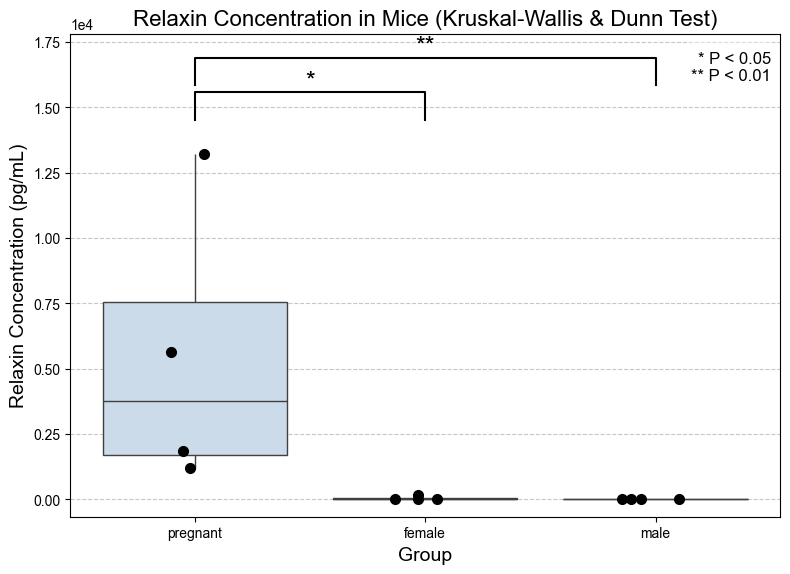

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# 1. データの準備 (変更なし)
data = {
    'Group': ['pregnant'] * 4 + ['female'] * 4 + ['male'] * 4,
    'Concentration': [13200, 5652, 1220.466, 1860.652, 
                      165.5491, 0, 0, 0, 
                      0, 0, 0, 0]
}
df = pd.DataFrame(data)
group_order = ['pregnant', 'female', 'male'] 
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

p_values = {
    ('pregnant', 'female'): 0.024218,
    ('pregnant', 'male'): 0.006704,
    ('female', 'male'): 0.992750
}

# 2. Box Plotの作成
plt.figure(figsize=(8, 6))

ax = sns.boxplot(x='Group', y='Concentration', data=df, 
                 palette="Blues",
                 order=group_order,
                 showcaps=False, 
                 whis=1.5,
                 fliersize=0 
                )
sns.stripplot(x='Group', y='Concentration', data=df, color='black', 
              jitter=0.15, size=7, linewidth=1, ax=ax, order=group_order)

# 3. 手動での有意差アノテーションの追加
y_max_data = df['Concentration'].max()

# *** 修正点A: Y軸の上限を事前に拡張する ***
# データ最大値 (13200) の約 30% 分の余白を上に確保します。
# これで、アノテーションを描画しても、グラフの縦方向が相対的に短くなるのを防ぎます。
y_lim_top_expanded = y_max_data * 1.35 # データの最大値の 135% を上限とする
ax.set_ylim(bottom=ax.get_ylim()[0], top=y_lim_top_expanded)


# アノテーション関数を修正 (Y軸の上限再調整を削除)
def add_annotation(ax, group1, group2, p_value, y_start_ratio, y_height_ratio, max_val, group_order):
    if p_value < 0.001:
        stars = '***'
    elif p_value < 0.01:
        stars = '**'
    elif p_value < 0.05:
        stars = '*'
    else:
        return

    group_map = {name: i for i, name in enumerate(group_order)}
    x1 = group_map[group1]
    x2 = group_map[group2]
    
    y_start = max_val * y_start_ratio
    y_height = max_val * y_height_ratio
    line_y = y_start 

    ax.plot([x1, x1, x2, x2], 
            [line_y, line_y + y_height, line_y + y_height, line_y], 
            lw=1.5, c='k')
    
    ax.text((x1 + x2) / 2, line_y + y_height, stars, 
            ha='center', va='bottom', color='k', fontsize=18)
    
    # *** 修正点B: set_ylim の再調整を削除。余白は事前に確保済み ***
    # グラフ描画中に自動でy_limが動かないようにする。

# ペアごとの注釈の追加
# y_start_ratio の値は、事前に確保した余白に合わせて微調整します。
# pregnant vs female (P = 0.024218 -> *)
add_annotation(ax, 'pregnant', 'female', p_values[('pregnant', 'female')], 
               y_start_ratio=1.1, y_height_ratio=0.08, max_val=y_max_data, group_order=group_order) # 1.1に調整

# pregnant vs male (P = 0.006704 -> **)
add_annotation(ax, 'pregnant', 'male', p_values[('pregnant', 'male')], 
               y_start_ratio=1.2, y_height_ratio=0.08, max_val=y_max_data, group_order=group_order) # 1.2に調整


# 4. タイトルとラベルの設定
plt.title('Relaxin Concentration in Mice (Kruskal-Wallis & Dunn Test)', fontsize=16)
plt.xlabel('Group', fontsize=14)
plt.ylabel('Relaxin Concentration (pg/mL)', fontsize=14)
# Y軸のスケールを固定したため、目盛りの自動調整を維持するために ticklabel_format はそのまま
plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0)) 

# *** 修正点：有意水準の凡例をグラフ内に手動で追加 ***
plt.text(x=2.5, # X座標：グラフの右端に近い位置
         y=y_max_data * 1.3, # Y座標：グラフの上部近く
         s="* P < 0.05\n** P < 0.01",
         ha='right', # 右揃え
         va='top',   # 上端合わせ
         fontsize=12,
         bbox=dict(facecolor='white', alpha=0.7, edgecolor='none', boxstyle='round,pad=0.5'))

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

C:\Users\a2189\AppData\Local\Temp\ipykernel_33020\4258741434.py:27: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  ax = sns.boxplot(x='Group', y='Concentration', data=df,


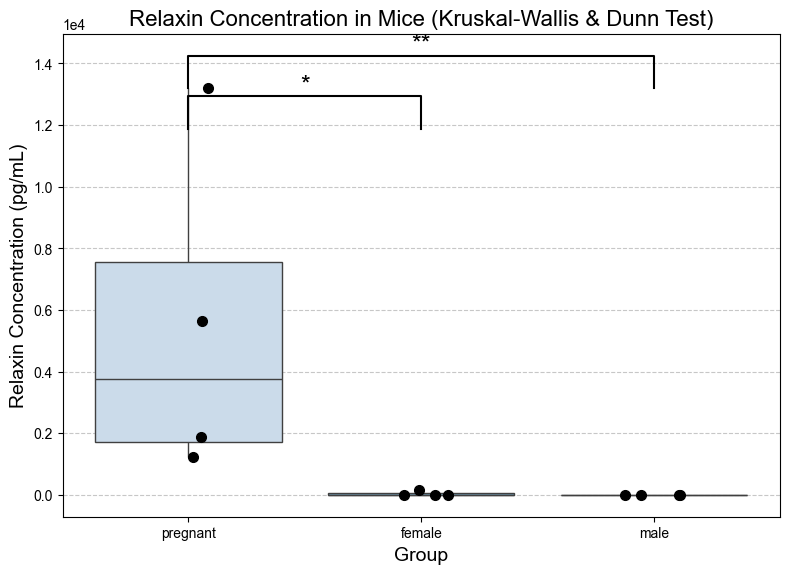

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# ... (データの準備と設定は変更なし) ...
data = {
    'Group': ['pregnant'] * 4 + ['female'] * 4 + ['male'] * 4,
    'Concentration': [13200, 5652, 1220.466, 1860.652, 
                      165.5491, 0, 0, 0, 
                      0, 0, 0, 0]
}
df = pd.DataFrame(data)
group_order = ['pregnant', 'female', 'male'] 
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Arial', 'DejaVu Sans']

p_values = {
    ('pregnant', 'female'): 0.024218,
    ('pregnant', 'male'): 0.006704,
    ('female', 'male'): 0.992750
}

# 2. Box Plotの作成 (変更なし)
plt.figure(figsize=(8, 6))

ax = sns.boxplot(x='Group', y='Concentration', data=df, 
                 palette="Blues", 
                 order=group_order,
                 showcaps=False, 
                 whis=1.5,
                 fliersize=0 
                )
sns.stripplot(x='Group', y='Concentration', data=df, color='black', 
              jitter=0.15, size=7, linewidth=1, ax=ax, order=group_order)

# 3. 手動での有意差アノテーションの追加
y_max_data = df['Concentration'].max()

# ... (add_annotation 関数は変更なし) ...
def add_annotation(ax, group1, group2, p_value, y_start_ratio, y_height_ratio, max_val, group_order):
    if p_value < 0.001:
        stars = '***'
    elif p_value < 0.01:
        stars = '**'
    elif p_value < 0.05:
        stars = '*'
    else:
        return

    group_map = {name: i for i, name in enumerate(group_order)}
    x1 = group_map[group1]
    x2 = group_map[group2]
    
    y_start = max_val * y_start_ratio
    y_height = max_val * y_height_ratio
    line_y = y_start 

    ax.plot([x1, x1, x2, x2], 
            [line_y, line_y + y_height, line_y + y_height, line_y], 
            lw=1.5, c='k')
    
    ax.text((x1 + x2) / 2, line_y + y_height, stars, 
            ha='center', va='bottom', color='k', fontsize=18)
    
    current_top = ax.get_ylim()[1]
    required_top = line_y + y_height * 1.5
    if required_top > current_top:
        ax.set_ylim(bottom=ax.get_ylim()[0], top=required_top)

# ペアごとの注釈の追加
# *** 修正点: y_start_ratio をさらに下げました (0.95 -> 0.90, 1.08 -> 1.0) ***
# pregnant vs female (P = 0.024218 -> *)
add_annotation(ax, 'pregnant', 'female', p_values[('pregnant', 'female')], 
               y_start_ratio=0.90, y_height_ratio=0.08, max_val=y_max_data, group_order=group_order)

# pregnant vs male (P = 0.006704 -> **)
add_annotation(ax, 'pregnant', 'male', p_values[('pregnant', 'male')], 
               y_start_ratio=1.00, y_height_ratio=0.08, max_val=y_max_data, group_order=group_order)


# 4. タイトルとラベルの設定 (変更なし)
plt.title('Relaxin Concentration in Mice (Kruskal-Wallis & Dunn Test)', fontsize=16)
plt.xlabel('Group', fontsize=14)
plt.ylabel('Relaxin Concentration (pg/mL)', fontsize=14)
plt.ticklabel_format(style='sci', axis='y', scilimits=(0, 0)) 

plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()